# CA1 charts: load the measured data and draw every figure

Every chart in the report and the slides comes from the test results saved on November 9, 2026, in [test-results](../../test-results/). This notebook loads that data, shows the numbers the report quotes, and draws the charts by calling the scripts in [scripts](../../scripts/):

- [ca1_charts.py](../../scripts/ca1_charts.py): CloudWatch panels, k6 request timelines, target health
- [ca1_compare_chart.py](../../scripts/ca1_compare_chart.py): one Product instance against two
- [ca1_chart_data.py](../../scripts/ca1_chart_data.py): the data file the interactive slide charts load

Run it from top to bottom (**Run All**). [ca1-make-charts.ps1](ca1-make-charts.ps1) draws the same pictures without Jupyter. The diagrams (architecture, timelines) are Mermaid, not here.

In [1]:
from pathlib import Path
import sys

# The chart scripts are in scripts/, two folders up from data/notebooks
sys.path.insert(0, str(Path.cwd().parents[1] / "scripts"))
import json
import pandas as pd
from IPython.display import Image, display

import ca1_charts
import ca1_compare_chart
import ca1_chart_data as data

ROOT = data.ROOT
FIGURES = ROOT / "docs" / "report-images"
run = {name: data.RESULTS / folder for name, folder in data.RUNS.items()}
pd.Series({name: path.name for name, path in run.items()}, name="folder in test-results")

one               20261109-184043-laptop-read-1product-400users
two               20261109-185537-laptop-read-2product-400users
failure        20261109-185653-laptop-failure-2product-100users
elasticity    20261109-191012-laptop-elasticity-1to2-cpu30-2...
Name: folder in test-results, dtype: str

## 1. The k6 summary of each run

What k6 measured on the laptop (the client): requests per second, client p95 (95% of requests finished faster than this) and the share of failed requests.

In [2]:
def summary(path):
    m = json.loads((path / "summary.json").read_text(encoding="utf-8-sig"))["metrics"]
    return {"requests": int(m["http_reqs"]["count"]), "requests per second": round(m["http_reqs"]["rate"], 1),
            "client p95 (ms)": round(m["http_req_duration"]["p(95)"], 1), "failed (%)": round(m["http_req_failed"]["value"] * 100, 2)}

pd.DataFrame({name: summary(path) for name, path in run.items()}).T

,requests,requests per second,client p95 (ms),failed (%)
one,73971.0,1170.4,533.7,0.50
two,74028.0,1171.5,577.1,0.47
failure,351652.0,976.6,180.0,1.28
elasticity,1242817.0,1478.9,365.3,0.02


## 2. One Product instance against two (report figure 17, slide 03)

Step load from 10 to 400 virtual users, one minute each. The client saw the same throughput with two instances: the laptop was the limit.

In [3]:
steps = data.one_vs_two()
table = pd.concat({name: pd.DataFrame(rows).set_index("users") for name, rows in steps.items()}, axis=1)
table.columns.names = ["", "measure"]
table

1 Product instance        2 Product instances       
measure                rps    p95                 rps    p95
users                                                       
10                   150.7   96.5               136.1   67.9
25                   276.9  104.8               287.0   81.7
50                   512.8  103.3               565.5  108.5
100                  719.6  137.4               665.5  209.7
200                 1019.9  294.9              1013.9  366.0
400                 1170.4  533.7              1171.5  577.1

1 Product instance
    10 users     150.7 req/s  p95    96.5 ms  errors 0.04%
    25 users     276.9 req/s  p95   104.8 ms  errors 0.13%
    50 users     512.8 req/s  p95   103.3 ms  errors 0.12%
   100 users     719.6 req/s  p95   137.4 ms  errors 0.24%
   200 users    1019.9 req/s  p95   294.9 ms  errors 0.27%
   400 users    1170.4 req/s  p95   533.7 ms  errors 0.50%
2 Product instances
    10 users     136.1 req/s  p95    67.9 ms  errors 0.10%
    25 users     287.0 req/s  p95    81.7 ms  errors 0.13%
    50 users     565.5 req/s  p95   108.5 ms  errors 0.07%
   100 users     665.5 req/s  p95   209.7 ms  errors 0.21%
   200 users    1013.9 req/s  p95   366.0 ms  errors 0.26%
   400 users    1171.5 req/s  p95   577.1 ms  errors 0.47%
Saved C:\Users\user\GitHub\the-moodler\coupon-product-java\docs\report-images\one-vs-two.png


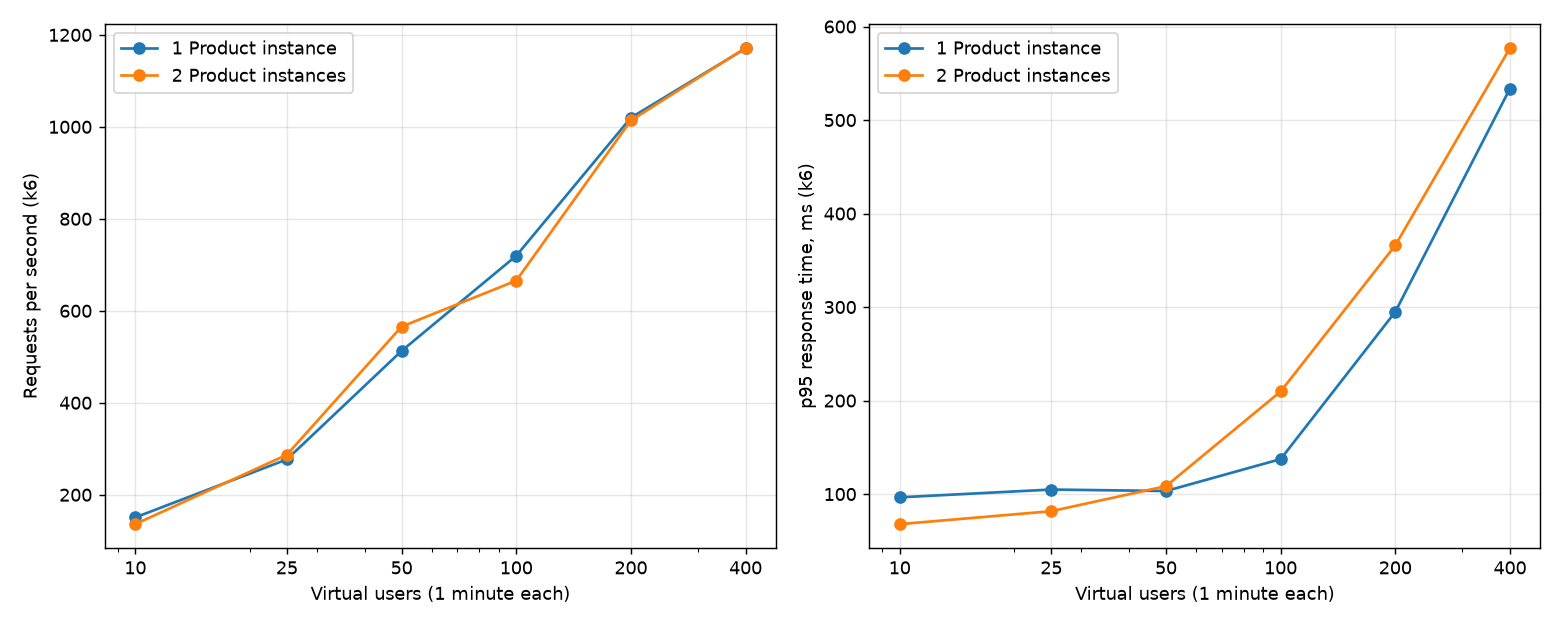

In [4]:
output = FIGURES / "one-vs-two.png"
!python ../../scripts/ca1_compare_chart.py --root ../../test-results --output "{output}"
display(Image(filename=output))

## 3. Elasticity: one to two instances under 200 users (report figure 12, slide 04)

Target tracking on average CPU at 30%. How long each step took:

In [5]:
ev = {label: ca1_charts.parse_time(when) for label, when in data.EVENTS["elasticity"]}
steps = list(ev.items())
pd.DataFrame([{"from": a, "to": b, "took": str(tb - ta)} for (a, ta), (b, tb) in zip(steps, steps[1:])])

,from,to,took
0,Load starts,Alarm: 1 to 2 instances,0:04:19
1,Alarm: 1 to 2 instances,New target healthy,0:01:32
2,New target healthy,Load ends,0:08:12


Saved C:\Users\user\GitHub\the-moodler\coupon-product-java\docs\report-images\elasticity-timeline.png


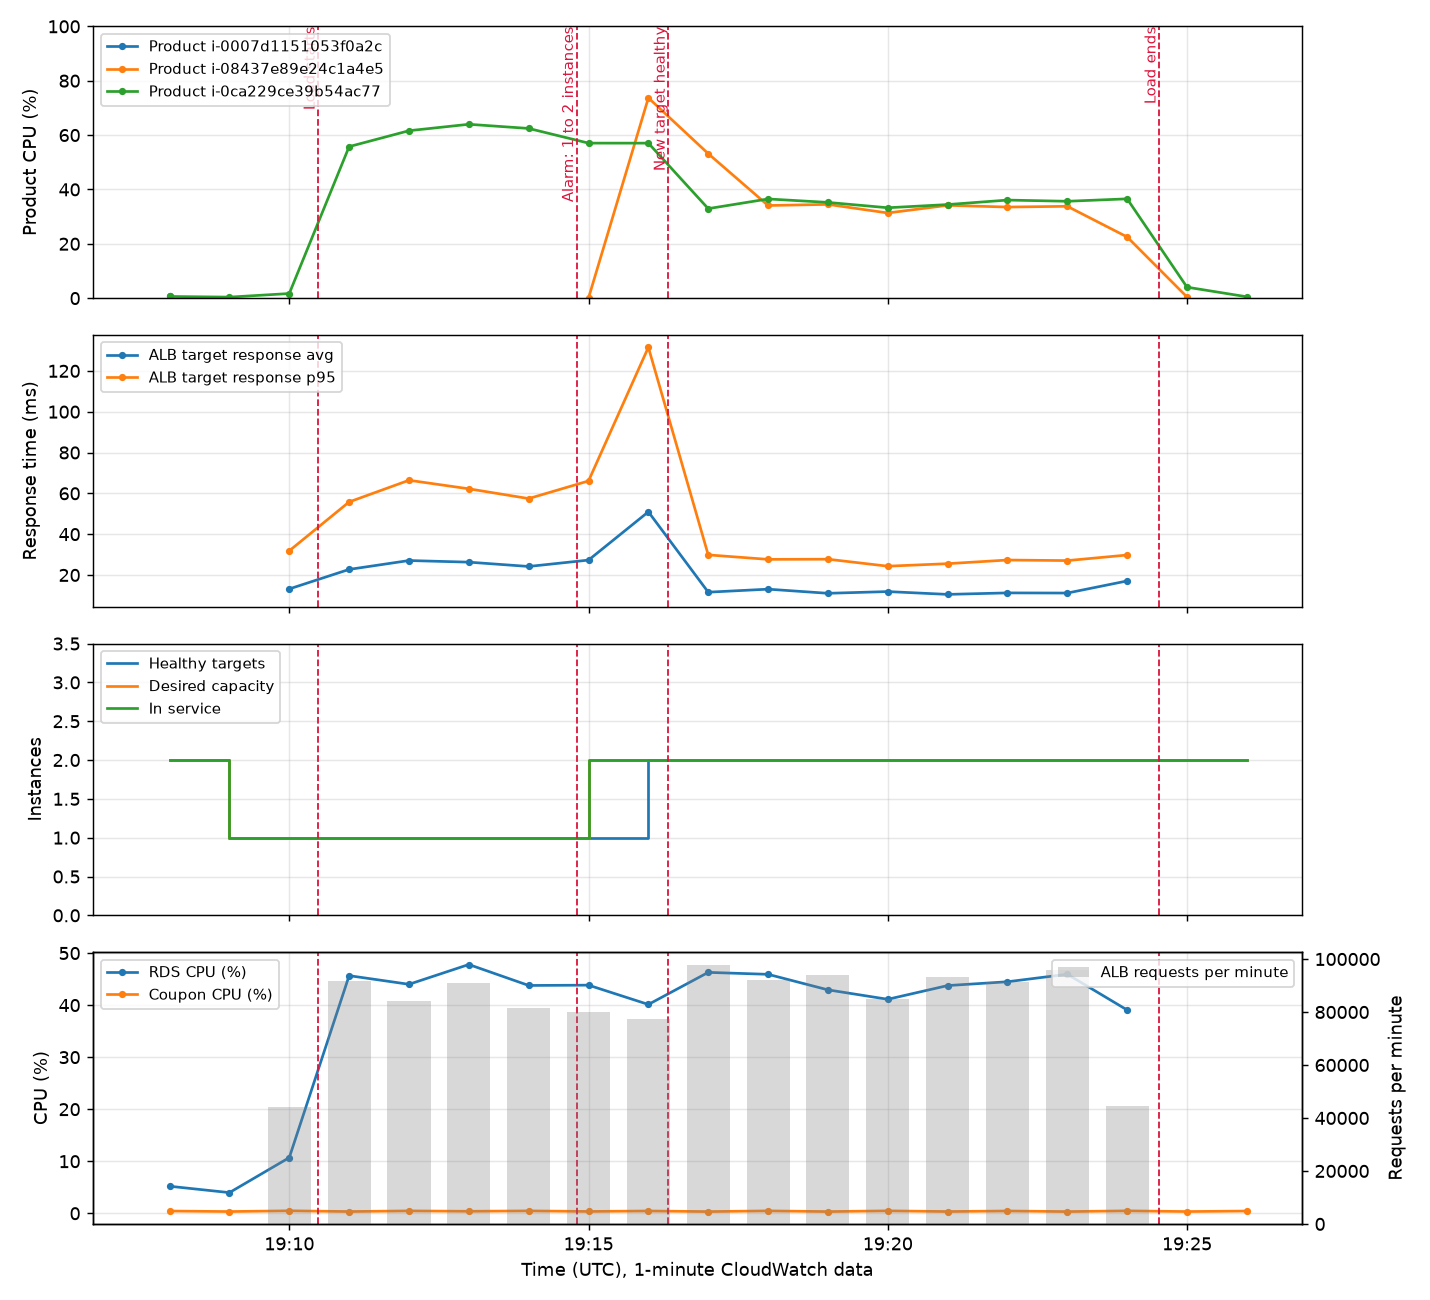

In [6]:
output = FIGURES / "elasticity-timeline.png"
ca1_charts.draw_metrics(run["elasticity"] / "metrics.json", output, "", list(ev.items()))
display(Image(filename=output))

## 4. Failure: one of two instances terminated under 100 users (report figure 15, slide 05)

k6 request samples in 5-second windows.

In [7]:
times, rate, failed, p95 = ca1_charts.timeline_buckets(run["failure"] / "samples.json.gz", 5)
windows = pd.DataFrame({"requests per second": rate, "failed requests": failed, "p95 (ms)": p95}, index=pd.DatetimeIndex(times, name="window (UTC)"))
print("Failed requests in total:", windows["failed requests"].sum())
windows[windows["failed requests"] > 100]

Failed requests in total: 4490


,requests per second,failed requests,p95 (ms)
window (UTC),,,
2026-11-09 18:59:20+00:00,1085.4,1965,149.4936
2026-11-09 18:59:25+00:00,905.2,2215,121.4042


Saved C:\Users\user\GitHub\the-moodler\coupon-product-java\docs\report-images\failure-client.png; requests 351652, failed 4490
Failures from 18:57:35 to 18:59:50 UTC


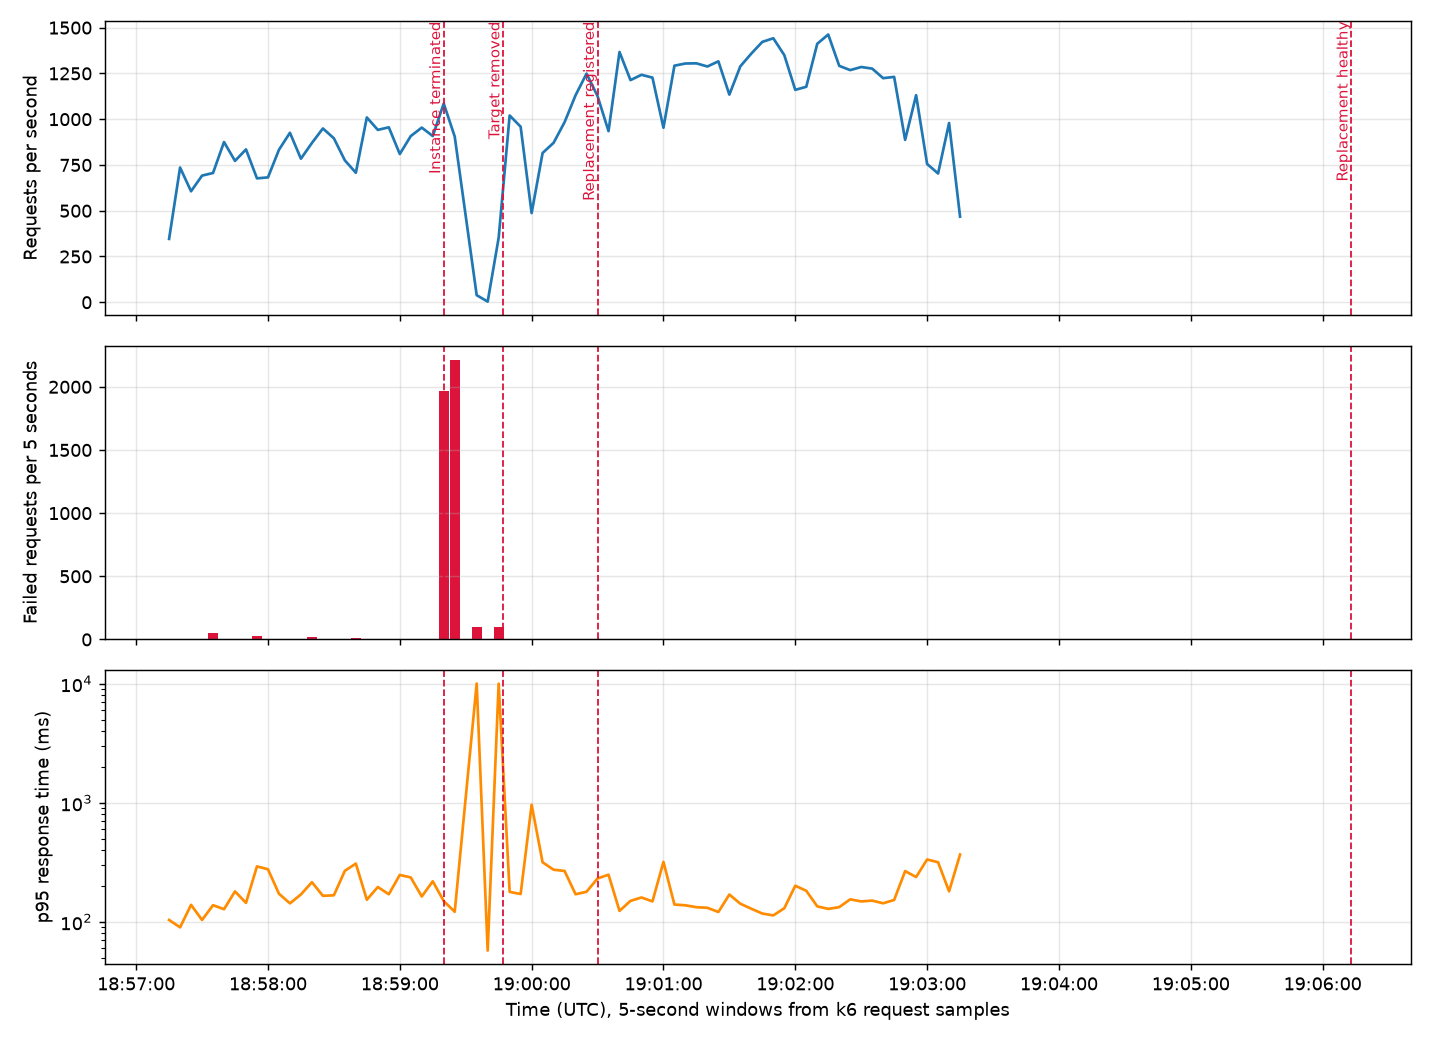

In [8]:
ev = [(label, ca1_charts.parse_time(when)) for label, when in data.EVENTS["failure"]]
output = FIGURES / "failure-client.png"
ca1_charts.draw_timeline(run["failure"] / "samples.json.gz", output, "", 5, ev)
display(Image(filename=output))

## 5. Data for the interactive slide charts

Writes [ca1-charts.json](../../docs/screencast-deck/data/ca1-charts.json), which slides 03, 04 and 05 load and draw in the browser.

In [9]:
exported = data.export()

Saved docs\screencast-deck\data\ca1-charts.json (6 KB)


## 6. Every other chart

Redraws the rest of the report's PNG charts (figures 10 to 15) and nothing else changes.

In [10]:
!pwsh -NoProfile -File ca1-make-charts.ps1

1 Product instance
    10 users     150.7 req/s  p95    96.5 ms  errors 0.04%
    25 users     276.9 req/s  p95   104.8 ms  errors 0.13%
    50 users     512.8 req/s  p95   103.3 ms  errors 0.12%
   100 users     719.6 req/s  p95   137.4 ms  errors 0.24%
   200 users    1019.9 req/s  p95   294.9 ms  errors 0.27%
   400 users    1170.4 req/s  p95   533.7 ms  errors 0.50%
2 Product instances
    10 users     136.1 req/s  p95    67.9 ms  errors 0.10%
    25 users     287.0 req/s  p95    81.7 ms  errors 0.13%
    50 users     565.5 req/s  p95   108.5 ms  errors 0.07%
   100 users     665.5 req/s  p95   209.7 ms  errors 0.21%
   200 users    1013.9 req/s  p95   366.0 ms  errors 0.26%
   400 users    1171.5 req/s  p95   577.1 ms  errors 0.47%
Saved docs\report-images\one-vs-two.png
1 Product instance
    10 users     150.7 req/s  p95    96.5 ms  errors 0.04%
    25 users     276.9 req/s  p95   104.8 ms  errors 0.13%
    50 users     512.8 req/s  p95   103.3 ms  errors 0.12%
   100 users     